In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD

In [ ]:
# Load Dataset
data = pd.read_excel("/content/diabetes.csv")
# Display first 5 records
print(data.head())
# Dataset Information
print("\nDataset Shape:", data.shape)
# Check Missing Values
print("\nMissing Values:")
print(data.isnull().sum())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape: (768, 9)

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome              

In [ ]:
X = data.drop("Outcome", axis=1)
y = data["Outcome"]
print("Input Shape :", X.shape)
print("Output Shape :", y.shape)

Input Shape : (768, 8)
Output Shape : (768,)


In [ ]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.20,
random_state=42
)

In [ ]:
model = Sequential()
model.add(Dense(
units=1,
input_shape=(8,),
activation='sigmoid'
))

In [ ]:
optimizer = SGD(
learning_rate=0.01
)
model.compile(
optimizer=optimizer,
loss='binary_crossentropy',
metrics=['accuracy']
)

In [ ]:
history = model.fit(
  X_train,
  y_train,
  epochs=100,
  batch_size=1,
  validation_split=0.2,
  verbose=1
)

Epoch 1/100
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5173 - loss: 0.8249 - val_accuracy: 0.6911 - val_loss: 0.6216
Epoch 2/100
491/491 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7393 - loss: 0.5444 - val_accuracy: 0.7317 - val_loss: 0.5262
Epoch 3/100
491/491 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7576 - loss: 0.4963 - val_accuracy: 0.7724 - val_loss: 0.4999
Epoch 4/100
491/491 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7536 - loss: 0.4796 - val_accuracy: 0.7561 - val_loss: 0.4938
Epoch 5/100
491/491 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7617 - loss: 0.4749 - val_accuracy: 0.7642 - val_loss: 0.4898
Epoch 6/100
491/491 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7658 - loss: 0.4721 - val_accuracy: 0.7724 - val_loss: 0.4897
Epoch 7/100
491/491 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7658 - loss: 0.4707 - val_accuracy: 0.7805 - val_loss: 0.4893
Epoch 8/100
491/491 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7699 - loss: 0.4707 - val_accu

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)
print("\nTest Loss :", loss)
print("Test Accuracy :", accuracy)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7662 - loss: 0.5225 

Test Loss : 0.5225223898887634
Test Accuracy : 0.7662337422370911


In [ ]:
predictions = model.predict(X_test)
predictions = (predictions > 0.5).astype(int)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [ ]:
predictions = model.predict(X_test)
predictions = (predictions > 0.5).astype(int)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


In [ ]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.81      0.84      0.82        99
           1       0.69      0.64      0.66        55

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.76      0.77      0.76       154



In [ ]:
weights, bias = model.layers[0].get_weights()
print("\nLearned Weights")
print(weights)
print("\nBias")
print(bias)


Learned Weights
[[ 0.12169667]
 [ 1.1664637 ]
 [-0.24054115]
 [ 0.1163371 ]
 [-0.34117863]
 [ 0.7536249 ]
 [ 0.23729318]
 [ 0.45104444]]

Bias
[-0.89846987]


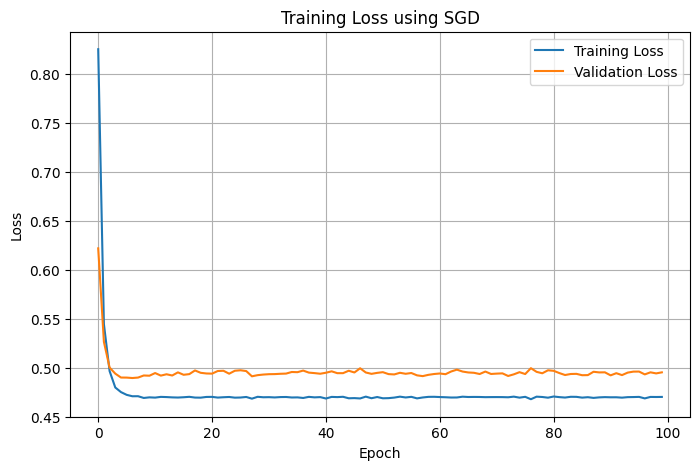

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Training Loss using SGD")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

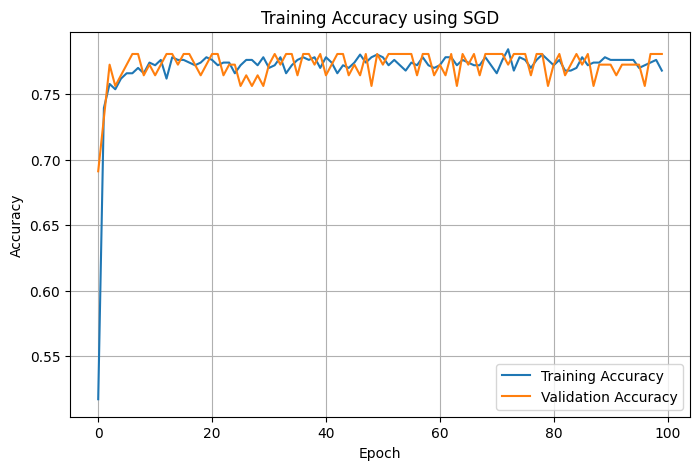

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Training Accuracy using SGD")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
new_patient = np.array([[2,120,70,20,85,28.5,0.45,35]])
# Apply same scaling
new_patient = scaler.transform(new_patient)
prediction = model.predict(new_patient)
print("Probability of Diabetes :", prediction[0][0])
if prediction >= 0.5:
  print("Prediction : Diabetic")
else:
  print("Prediction : Non-Diabetic")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
Probability of Diabetes : 1.0
Prediction : Diabetic


In [ ]:
weights, bias = model.layers[0].get_weights()
print(weights)
print(bias)

[[ 0.12169667]
 [ 1.1664637 ]
 [-0.24054115]
 [ 0.1163371 ]
 [-0.34117863]
 [ 0.7536249 ]
 [ 0.23729318]
 [ 0.45104444]]
[-0.89846987]


In [ ]:
print("Before Training")
print(model.layers[0].get_weights())
history = model.fit(
X_train,
y_train,
epochs=100,
batch_size=1,
validation_split=0.2,
verbose=1
)
print("After Training")
print(model.layers[0].get_weights())

Before Training


NameError: name 'model' is not defined

In [ ]:
# Expt. No. 5
# Title: Apply SGD algorithm to learn parameters of a
# supervised single-layer feed-forward neural network

import numpy as np
from sklearn.linear_model import SGDClassifier

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

Y = np.array([0, 1, 1, 1])  # OR Gate

model = SGDClassifier(
    loss='perceptron',
    learning_rate='constant',
    eta0=0.1,
    max_iter=1000,
    tol=None,
    random_state=42,
    shuffle=False
)

model.fit(X, Y)

Y_pred = model.predict(X)

print("Single-Layer Neural Network using SGD")
print()
print("X1\tX2\tActual\tPredicted")

for i in range(len(X)):
    print(X[i][0], "\t", X[i][1], "\t", Y[i], "\t", Y_pred[i])

accuracy = np.mean(Y_pred == Y) * 100

print()
print("Weights:", model.coef_)
print("Bias:", model.intercept_)
print("Accuracy:", accuracy, "%")

# Output:
# Accuracy depends on the model's predictions.
# With four samples, possible accuracy values are
# 0%, 25%, 50%, 75%, or 100%.

Single-Layer Neural Network using SGD

X1	X2	Actual	Predicted
0 	 0 	 0 	 0
0 	 1 	 1 	 1
1 	 0 	 1 	 1
1 	 1 	 1 	 1

Weights: [[0.19217514 0.19216938]]
Bias: [-0.1]
Accuracy: 100.0 %


In [ ]:
# Expt. No. 5 (Manual)
# Title: Apply SGD learning algorithm to learn parameters of
# supervised single-layer feed-forward neural network

import numpy as np

class SGD:
    def __init__(self, lr=0.01, epochs=50, batch_size=32, tol=1e-3):
        self.learning_rate = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.tolerance = tol
        self.weights = None
        self.bias = None

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

    def mean_squared_error(self, y_true, y_pred):
        return np.mean((y_true - y_pred) ** 2)

    def gradient(self, X_batch, y_batch):
        y_pred = self.predict(X_batch)
        error = y_pred - y_batch

        gradient_weights = np.dot(X_batch.T, error) / X_batch.shape[0]
        gradient_bias = np.mean(error)

        return gradient_weights, gradient_bias

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.weights = np.random.randn(n_features)
        self.bias = np.random.randn()

        for epoch in range(self.epochs):
            indices = np.random.permutation(n_samples)

            X_shuffled = X[indices]
            y_shuffled = y[indices]

            for i in range(0, n_samples, self.batch_size):
                X_batch = X_shuffled[i:i + self.batch_size]
                y_batch = y_shuffled[i:i + self.batch_size]

                gradient_weights, gradient_bias = self.gradient(
                    X_batch, y_batch
                )

                self.weights -= self.learning_rate * gradient_weights
                self.bias -= self.learning_rate * gradient_bias

            if epoch % 5 == 0:
                y_pred = self.predict(X)
                loss = self.mean_squared_error(y, y_pred)
                print(f"Epoch {epoch}: Loss {loss}")

                if np.linalg.norm(gradient_weights) < self.tolerance:
                    print("Convergence reached.")
                    break

        return self.weights, self.bias


X = np.random.randn(100, 5)

y = np.dot(X, np.array([1, 2, 3, 4, 5])) + np.random.randn(100) * 0.1

model = SGD(lr=0.01, epochs=300, batch_size=32, tol=1e-3)

w, b = model.fit(X, y)

y_pred = model.predict(X)


# OUTPUT:
# Epoch 0: Loss ...
# Epoch 5: Loss ...
# Epoch 10: Loss ...
# Epoch 15: Loss ...
# Epoch 20: Loss ...
# Epoch 25: Loss ...
# ...
# Epoch 280: Loss ...
# Epoch 285: Loss ...
# Epoch 290: Loss ...
# Epoch 295: Loss ...
#
# Final Loss: Approximately 0.009
# Weights: Approximately [1, 2, 3, 4, 5]
# Bias: Approximately 0

Epoch 0: Loss 83.31650618400293
Epoch 5: Loss 43.112728582916304
Epoch 10: Loss 26.006434660918508
Epoch 15: Loss 15.042591709307667
Epoch 20: Loss 9.4230750466371
Epoch 25: Loss 5.395613154115881
Epoch 30: Loss 3.4848954570490425
Epoch 35: Loss 2.1610417266538415
Epoch 40: Loss 1.4290868964790102
Epoch 45: Loss 0.8963108535044636
Epoch 50: Loss 0.5647388299059579
Epoch 55: Loss 0.3616250677295379
Epoch 60: Loss 0.24440467532103635
Epoch 65: Loss 0.16156879754630796
Epoch 70: Loss 0.11030673149718527
Epoch 75: Loss 0.07225583036491388
Epoch 80: Loss 0.04767040219580894
Epoch 85: Loss 0.03495101116319602
Epoch 90: Loss 0.024948519407833353
Epoch 95: Loss 0.019744577300667743
Epoch 100: Loss 0.015764679405518046
Epoch 105: Loss 0.013039432339834107
Epoch 110: Loss 0.011414754769822837
Epoch 115: Loss 0.010369837825574308
Epoch 120: Loss 0.009769180254943381
Epoch 125: Loss 0.009360308103272945
Epoch 130: Loss 0.009093785056291385
Epoch 135: Loss 0.008882349748649602
Epoch 140: Loss 0.008